<a href="https://colab.research.google.com/github/RoqueThis/MachineLearning/blob/main/Roquemore_starter_housing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Imports
import polars as pl
import numpy as np
import xgboost as xgb
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from plotnine import ggplot, aes, geom_boxplot, labs, theme_bw, element_text, scale_x_discrete, geom_dotplot, geom_line, geom_point, theme


In [5]:
housing = pl.read_csv('https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/housing.csv')

housing.glimpse()

Rows: 1613
Columns: 20
$ id            <i64> 2591820310, 7974200820, 7701450110, 9522300010, 9510861140, 1761300310, 7732410120, 7010701383, 291310170, 4232901990
$ date          <str> '20141006T000000', '20140821T000000', '20140815T000000', '20150331T000000', '20140714T000000', '20140827T000000', '20140819T000000', '20141017T000000', '20140804T000000', '20140516T000000'
$ bedrooms      <i64> 4, 5, 4, 3, 3, 4, 4, 3, 3, 2
$ bathrooms     <f64> 2.25, 3.0, 2.5, 3.5, 2.5, 2.0, 2.5, 2.5, 2.5, 1.0
$ sqft_living   <i64> 2070, 2900, 3770, 4560, 2550, 1710, 2690, 1800, 1600, 910
$ sqft_lot      <i64> 8893, 6730, 10893, 14608, 5376, 8288, 8036, 4400, 2610, 3600
$ floors        <f64> 2.0, 1.0, 2.0, 2.0, 2.0, 1.5, 2.0, 1.0, 2.0, 1.0
$ waterfront    <i64> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0
$ view          <i64> 0, 0, 2, 2, 0, 0, 0, 0, 0, 0
$ condition     <i64> 4, 5, 3, 3, 3, 3, 4, 5, 3, 4
$ grade         <i64> 8, 8, 11, 12, 9, 7, 9, 7, 8, 7
$ sqft_above    <i64> 2070, 1830, 3770, 4560, 2550, 1710, 2690,

In [6]:
## Model

feature_cols = [col for col in housing.columns if col not in ['id', 'date', 'price']]
target_col = 'price'

X = housing.select(feature_cols).to_pandas()
y = housing.select(target_col).to_numpy().ravel()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=1,
    colsample_bytree=1,
    random_state=50
)

model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=100
)

y_pred = model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Model Performance")
print(f"RMSE: ${rmse:,.2f}")
print(f"R² Score: {r2:.4f}")

[0]	validation_0-rmse:375734.49027
[100]	validation_0-rmse:143456.73634
[200]	validation_0-rmse:137689.74937
[300]	validation_0-rmse:135679.02638
[400]	validation_0-rmse:134877.18246
[499]	validation_0-rmse:134099.01531
Model Performance
RMSE: $134,099.02
R² Score: 0.8808


In [14]:
testing = pl.read_csv('https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/housing_holdout_test.csv')

feature_cols = [col for col in X_train.columns]
X_holdout = testing.select(feature_cols).to_pandas()
predictions = model.predict(X_holdout)

formatted_predictions = [f"${x:,.2f}" for x in predictions]

results = testing.with_columns(
    pl.Series("predictions", formatted_predictions)
)
print(results.select(['id', 'grade', 'waterfront', 'zipcode', 'predictions']))

results.write_csv('team8-module2-predictions.csv')

shape: (1_613, 5)
┌────────────┬───────┬────────────┬─────────┬───────────────┐
│ id         ┆ grade ┆ waterfront ┆ zipcode ┆ predictions   │
│ ---        ┆ ---   ┆ ---        ┆ ---     ┆ ---           │
│ i64        ┆ i64   ┆ i64        ┆ i64     ┆ str           │
╞════════════╪═══════╪════════════╪═════════╪═══════════════╡
│ 2591820310 ┆ 8     ┆ 0          ┆ 98058   ┆ $387,580.00   │
│ 7974200820 ┆ 8     ┆ 0          ┆ 98115   ┆ $907,124.75   │
│ 7701450110 ┆ 11    ┆ 0          ┆ 98006   ┆ $1,171,501.50 │
│ 9522300010 ┆ 12    ┆ 0          ┆ 98034   ┆ $2,064,361.25 │
│ 9510861140 ┆ 9     ┆ 0          ┆ 98052   ┆ $703,368.00   │
│ …          ┆ …     ┆ …          ┆ …       ┆ …             │
│ 4322500110 ┆ 8     ┆ 0          ┆ 98136   ┆ $624,271.62   │
│ 7694200070 ┆ 8     ┆ 0          ┆ 98146   ┆ $451,231.66   │
│ 9321010130 ┆ 8     ┆ 0          ┆ 98022   ┆ $264,787.41   │
│ 3204300455 ┆ 11    ┆ 0          ┆ 98112   ┆ $1,285,594.88 │
│ 6706000040 ┆ 7     ┆ 0          ┆ 98148   ┆ $288,9

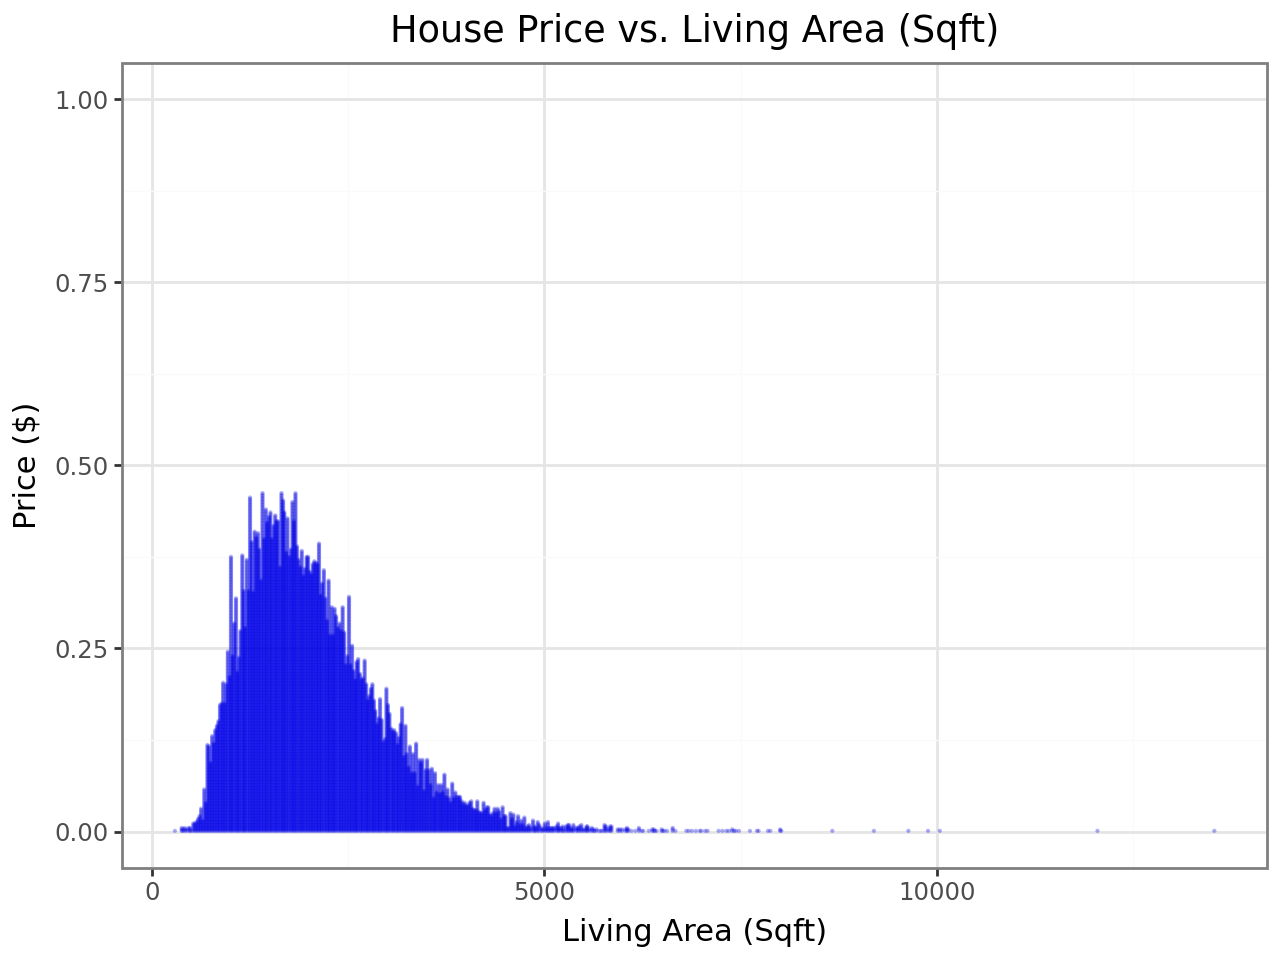

In [ ]:
housing_pd = housing.to_pandas()

(ggplot(data = housing_pd, mapping = aes(x = 'sqft_living', y = 'price')) +
 geom_dotplot(binwidth = 20, color = 'blue', alpha = 0.3) +
 labs(
     title = "House Price vs. Living Area (Sqft)",
     x = "Living Area (Sqft)",
     y = "Price ($)"
 ) +
 theme_bw())

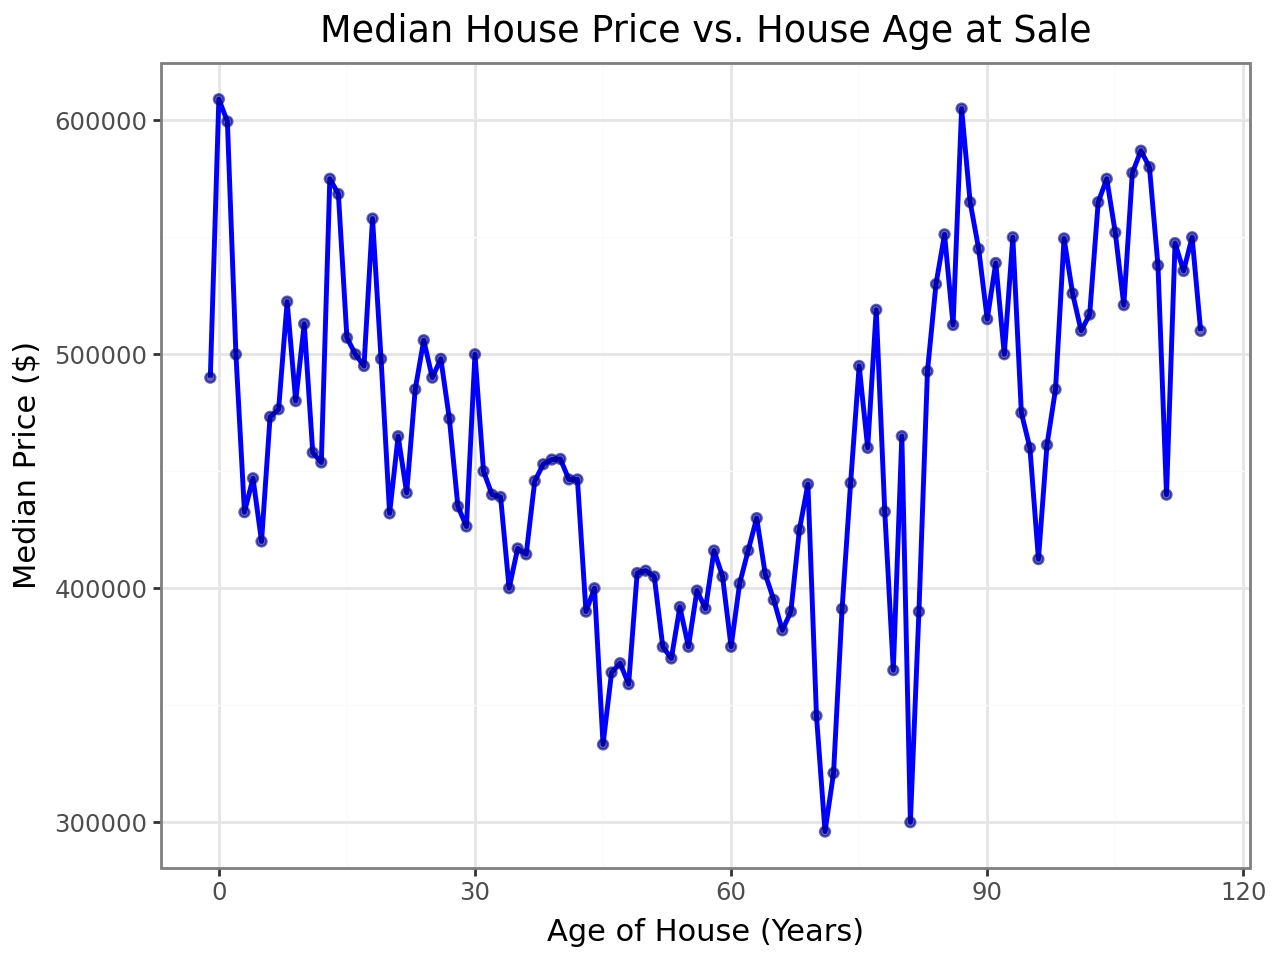

In [ ]:
housing_with_age = housing.with_columns([
    (pl.col("date").str.slice(0, 4).cast(pl.Int64) - pl.col("yr_built")).alias("age")
])

age_price_comparison = (
    housing_with_age.group_by("age")
    .agg(pl.col("price").median().alias("median_price"))
    .sort("age")
    .to_pandas()
)

(ggplot(data = age_price_comparison, mapping = aes(x = 'age', y = 'median_price')) +
 geom_line(color = 'blue', size = 1) +
 geom_point(color = 'darkblue', alpha = 0.6) +
 labs(
     title = "Median House Price vs. House Age at Sale",
     x = "Age of House (Years)",
     y = "Median Price ($)"
 ) +
 theme_bw())

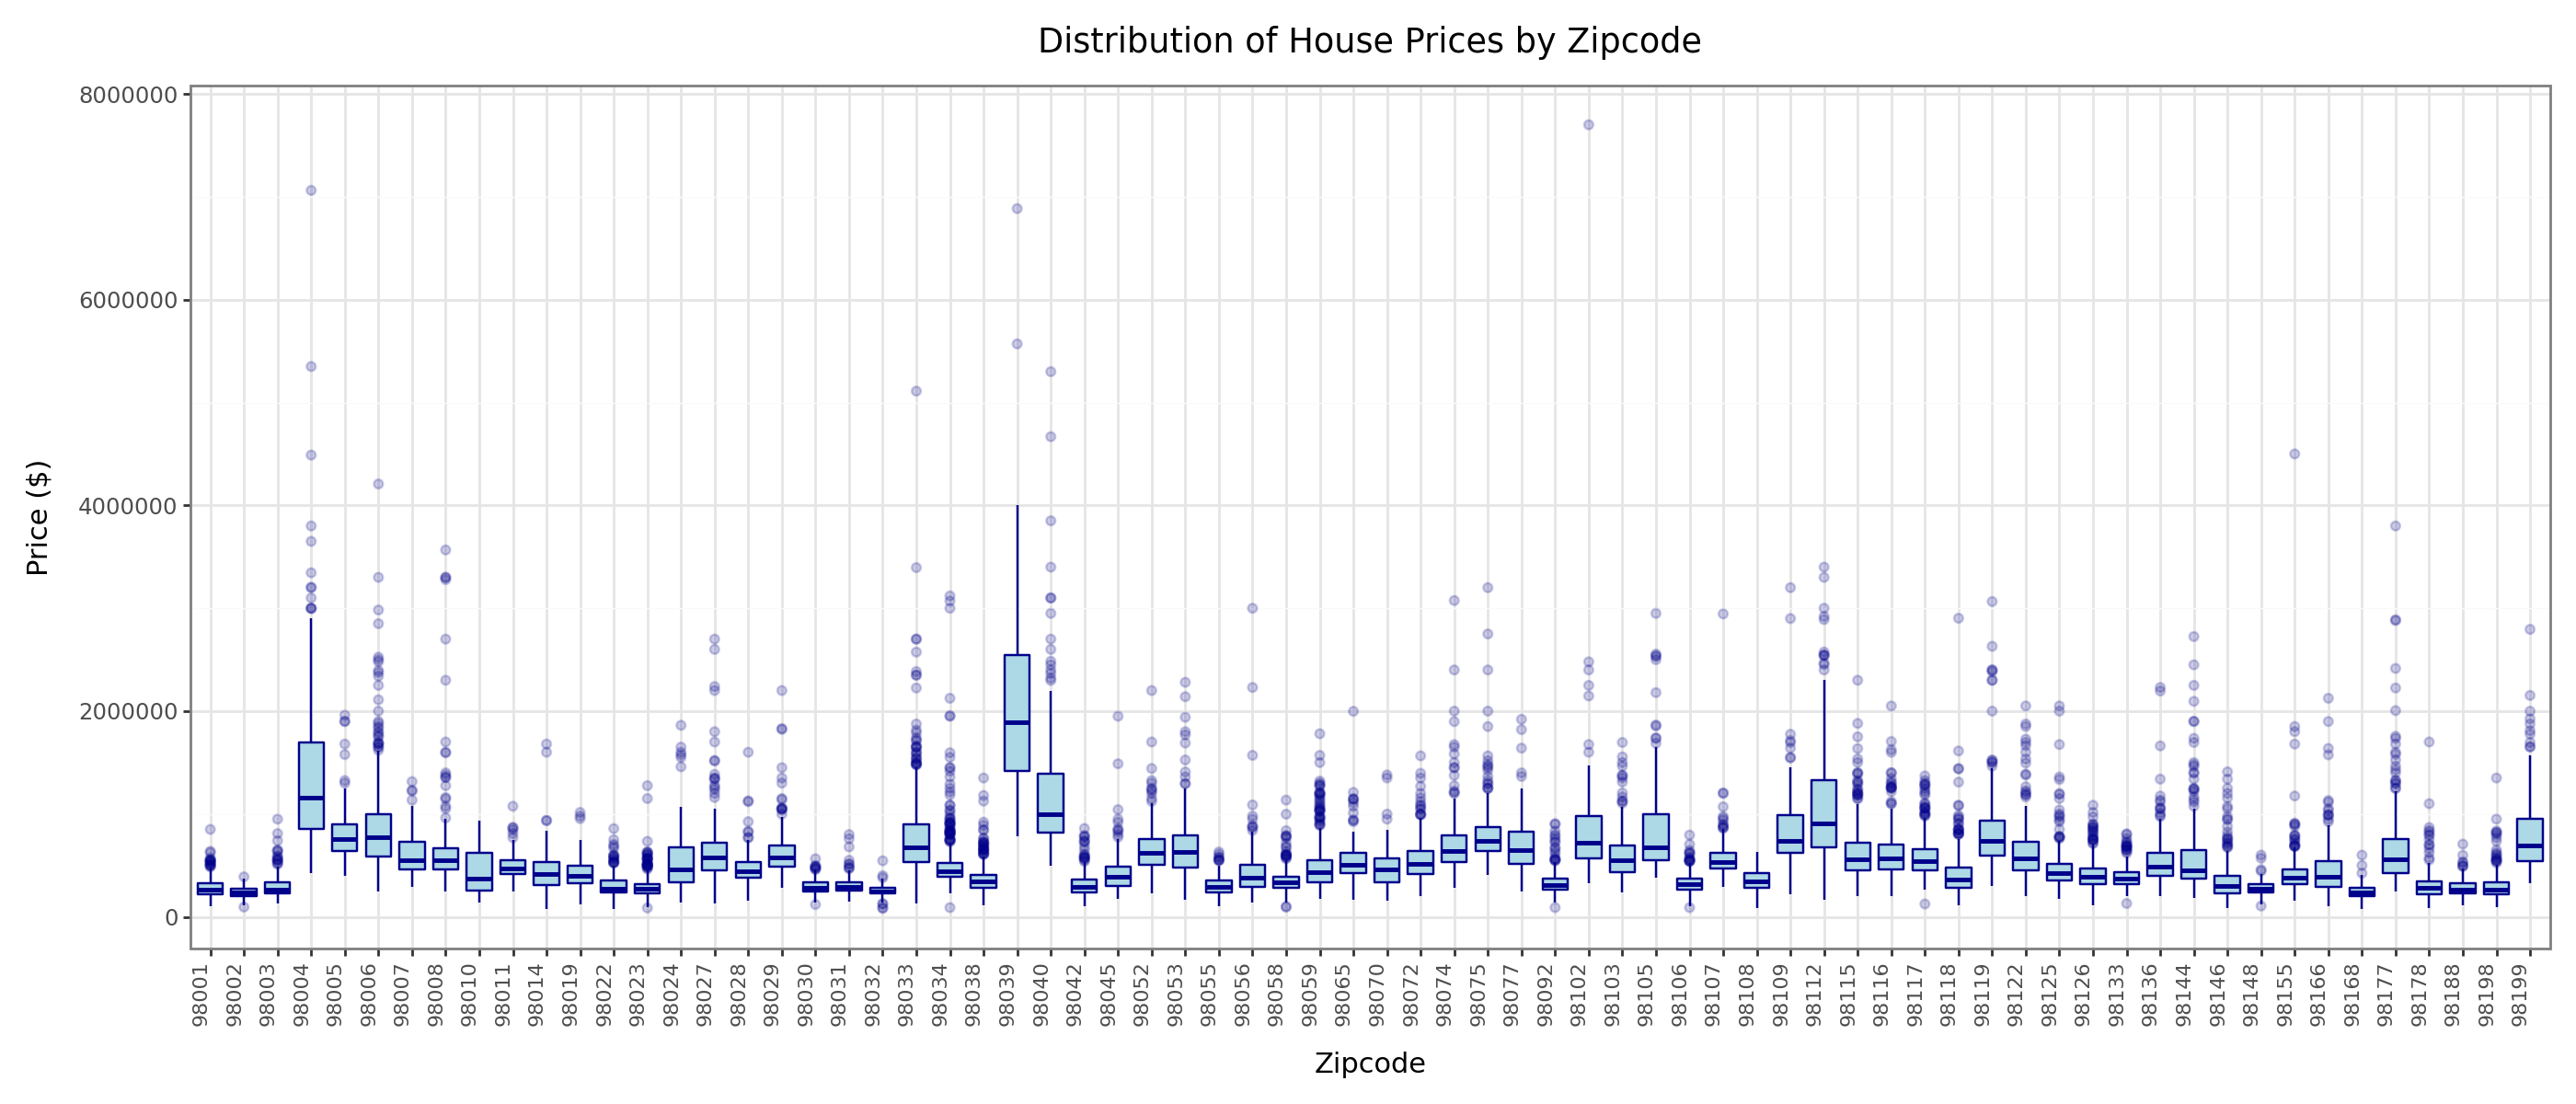

In [ ]:
housing_pd['zipcode_str'] = housing_pd['zipcode'].astype(str)

(ggplot(data = housing_pd, mapping = aes(x = 'zipcode_str', y = 'price')) +
 geom_boxplot(fill = 'lightblue', color = 'darkblue', outlier_alpha = 0.2) +
 labs(
     title = "Distribution of House Prices by Zipcode",
     x = "Zipcode",
     y = "Price ($)"
 ) +
 theme_bw() +
 theme(
     axis_text_x = element_text(rotation = 90, hjust = 1, size = 8),
     figure_size = (14, 6)
 ))